In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, GRU, Dense

In [2]:
df = pd.read_csv(r"C:\Users\hp\Downloads\AirPassengers (1).csv")

df.head()

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [3]:
df['Month'] = pd.to_datetime(df['Month'])

df.head()

,Month,#Passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


In [4]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Month        144 non-null    datetime64[ns]
 1   #Passengers  144 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.4 KB
None
                     Month  #Passengers
count                  144   144.000000
mean   1954-12-16 05:00:00   280.298611
min    1949-01-01 00:00:00   104.000000
25%    1951-12-24 06:00:00   180.000000
50%    1954-12-16 12:00:00   265.500000
75%    1957-12-08 18:00:00   360.500000
max    1960-12-01 00:00:00   622.000000
std                    NaN   119.966317


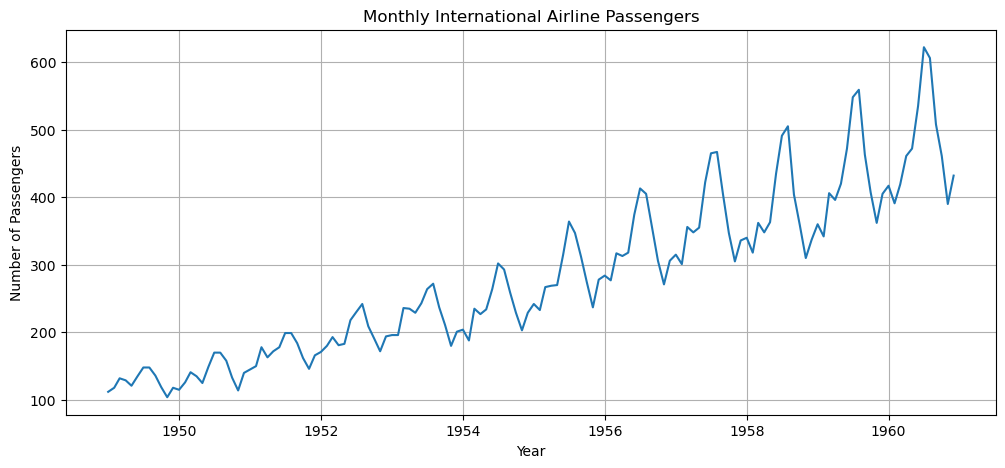

In [5]:
plt.figure(figsize=(12,5))

plt.plot(df['Month'], df['#Passengers'])

plt.title('Monthly International Airline Passengers')
plt.xlabel('Year')
plt.ylabel('Number of Passengers')

plt.grid(True)
plt.show()

In [6]:
data = df['#Passengers'].values.reshape(-1, 1)

print("Data shape:", data.shape)

Data shape: (144, 1)


In [7]:
scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(data)

print(scaled_data[:5])

[[0.01544402]
 [0.02702703]
 [0.05405405]
 [0.04826255]
 [0.03281853]]


In [8]:
train_size = int(len(scaled_data) * 0.80)

train_data = scaled_data[:train_size]
test_data = scaled_data[train_size:]

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

Training observations: 115
Testing observations: 29


In [9]:
window = 12

def create_sequences(data, window):
    X = []
    y = []

    for i in range(len(data) - window):
        X.append(data[i:i + window])
        y.append(data[i + window])

    return np.array(X), np.array(y)

In [10]:
X_train, y_train = create_sequences(train_data, window)

X_test, y_test = create_sequences(test_data, window)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (103, 12, 1)
y_train shape: (103, 1)
X_test shape: (17, 12, 1)
y_test shape: (17, 1)


In [11]:
lstm_model = Sequential([
    Input(shape=(window, 1)),
    LSTM(50, activation='tanh'),
    Dense(1)
])

lstm_model.compile(
    optimizer='adam',
    loss='mse'
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0678 - val_loss: 0.0952
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0147 - val_loss: 0.0235
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0089 - val_loss: 0.0429
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0080 - val_loss: 0.0246
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0072 - val_loss: 0.0264
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0064 - val_loss: 0.0240
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0063 - val_loss: 0.0240
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0063 - val_loss: 0.0236
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0060 - val_loss: 0.0234
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0060 - val_loss: 0.0228
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0059 - val_loss: 0.0225
Epoch 12/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss

In [13]:
lstm_predictions_scaled = lstm_model.predict(X_test)

lstm_predictions = scaler.inverse_transform(
    lstm_predictions_scaled
)

actual = scaler.inverse_transform(y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step


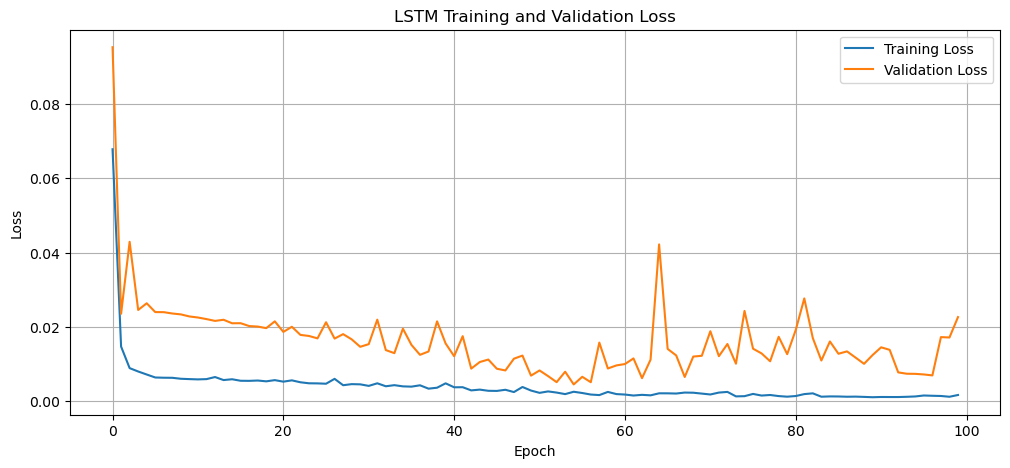

In [14]:
plt.figure(figsize=(12,5))

plt.plot(
    lstm_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    lstm_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('LSTM Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)

plt.show()

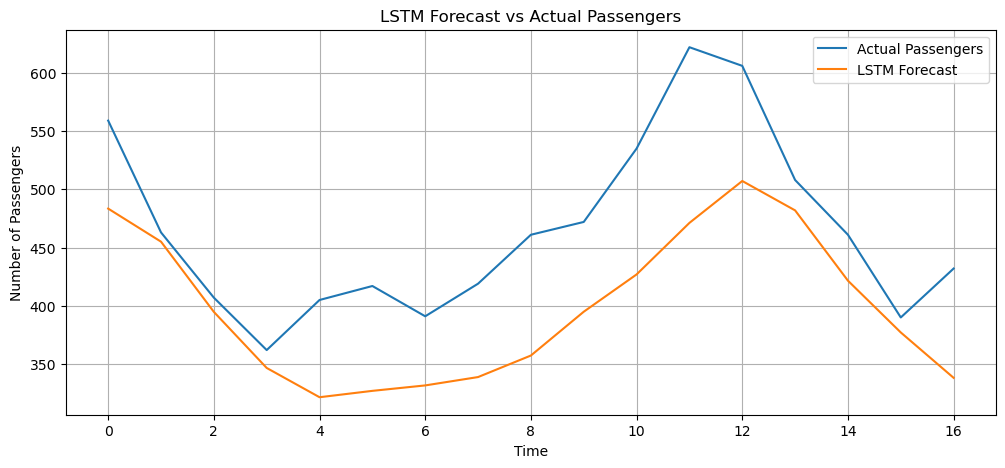

In [15]:
plt.figure(figsize=(12,5))

plt.plot(
    actual,
    label='Actual Passengers'
)

plt.plot(
    lstm_predictions,
    label='LSTM Forecast'
)

plt.title('LSTM Forecast vs Actual Passengers')
plt.xlabel('Time')
plt.ylabel('Number of Passengers')

plt.legend()
plt.grid(True)

plt.show()

In [16]:
gru_model = Sequential([
    Input(shape=(window, 1)),
    GRU(50, activation='tanh'),
    Dense(1)
])

gru_model.compile(
    optimizer='adam',
    loss='mse'
)

gru_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 50)             │         7,950 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,001 (31.25 KB)

 Trainable params: 8,001 (31.25 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0227 - val_loss: 0.0226
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0098 - val_loss: 0.0351
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0078 - val_loss: 0.0272
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0064 - val_loss: 0.0219
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0059 - val_loss: 0.0219
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0057 - val_loss: 0.0207
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0054 - val_loss: 0.0201
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0053 - val_loss: 0.0194
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0054 - val_loss: 0.0187
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0058 - val_loss: 0.0194
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0052 - val_loss: 0.0172
Epoch 12/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

In [18]:
gru_predictions_scaled = gru_model.predict(X_test)

gru_predictions = scaler.inverse_transform(
    gru_predictions_scaled
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step


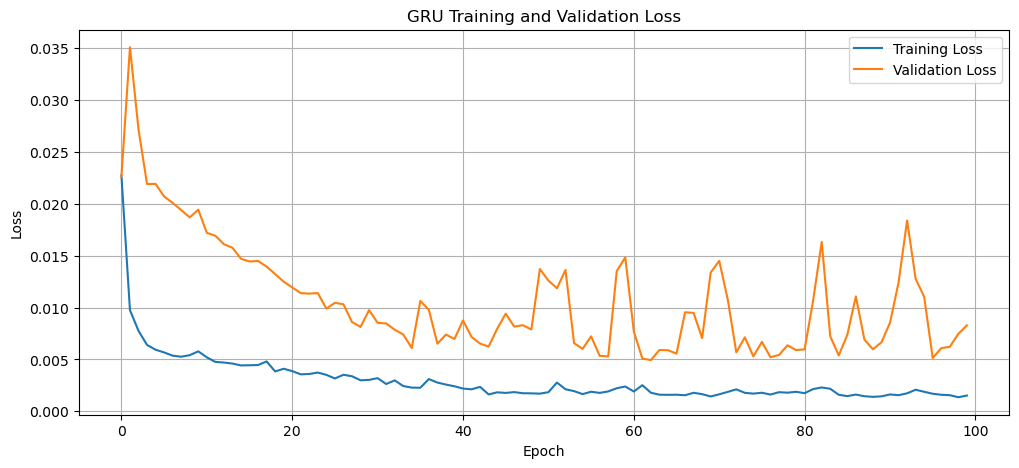

In [19]:
plt.figure(figsize=(12,5))

plt.plot(
    gru_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    gru_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('GRU Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)

plt.show()

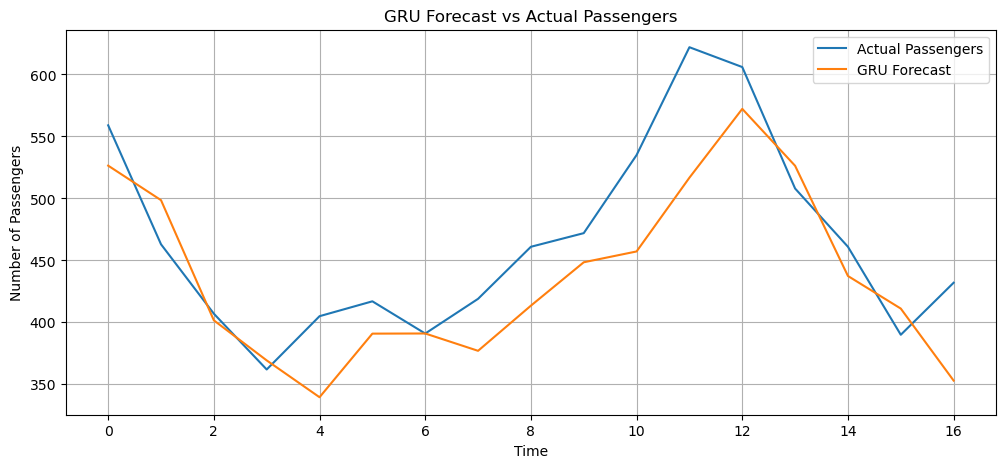

In [20]:
plt.figure(figsize=(12,5))

plt.plot(
    actual,
    label='Actual Passengers'
)

plt.plot(
    gru_predictions,
    label='GRU Forecast'
)

plt.title('GRU Forecast vs Actual Passengers')
plt.xlabel('Time')
plt.ylabel('Number of Passengers')

plt.legend()
plt.grid(True)

plt.show()

In [21]:
comparison = pd.DataFrame({
    'Actual': actual.ravel(),
    'LSTM_Forecast': lstm_predictions.ravel(),
    'GRU_Forecast': gru_predictions.ravel()
})

comparison.head(10)

,Actual,LSTM_Forecast,GRU_Forecast
0,559.0,483.448334,526.455750
1,463.0,455.055786,498.607178
2,407.0,394.775726,401.638184
3,362.0,346.646210,369.330078
4,405.0,321.521515,339.621826
5,417.0,326.983978,390.926117
6,391.0,331.652588,391.045013
7,419.0,338.831421,377.062622
8,461.0,357.321564,413.495819
9,472.0,394.915955,448.496857


In [22]:
lstm_mae = mean_absolute_error(
    actual.ravel(),
    lstm_predictions.ravel()
)

gru_mae = mean_absolute_error(
    actual.ravel(),
    gru_predictions.ravel()
)

print("LSTM MAE:", lstm_mae)
print("GRU MAE:", gru_mae)

LSTM MAE: 66.75297815659466
GRU MAE: 37.88642614028033


In [23]:
lstm_rmse = np.sqrt(
    mean_squared_error(
        actual.ravel(),
        lstm_predictions.ravel()
    )
)

gru_rmse = np.sqrt(
    mean_squared_error(
        actual.ravel(),
        gru_predictions.ravel()
    )
)

print("LSTM RMSE:", lstm_rmse)
print("GRU RMSE:", gru_rmse)

LSTM RMSE: 77.93957753264664
GRU RMSE: 47.13712875349677


In [24]:
lstm_mape = np.mean(
    np.abs(
        (actual.ravel() - lstm_predictions.ravel())
        / actual.ravel()
    )
) * 100

gru_mape = np.mean(
    np.abs(
        (actual.ravel() - gru_predictions.ravel())
        / actual.ravel()
    )
) * 100

print("LSTM MAPE:", lstm_mape, "%")
print("GRU MAPE:", gru_mape, "%")

LSTM MAPE: 13.957423530106347 %
GRU MAPE: 7.882607360653305 %


In [25]:
results = pd.DataFrame({
    'Model': [
        'LSTM',
        'GRU'
    ],
    'MAE': [
        lstm_mae,
        gru_mae
    ],
    'RMSE': [
        lstm_rmse,
        gru_rmse
    ],
    'MAPE (%)': [
        lstm_mape,
        gru_mape
    ]
})

results

,Model,MAE,RMSE,MAPE (%)
0,LSTM,66.752978,77.939578,13.957424
1,GRU,37.886426,47.137129,7.882607


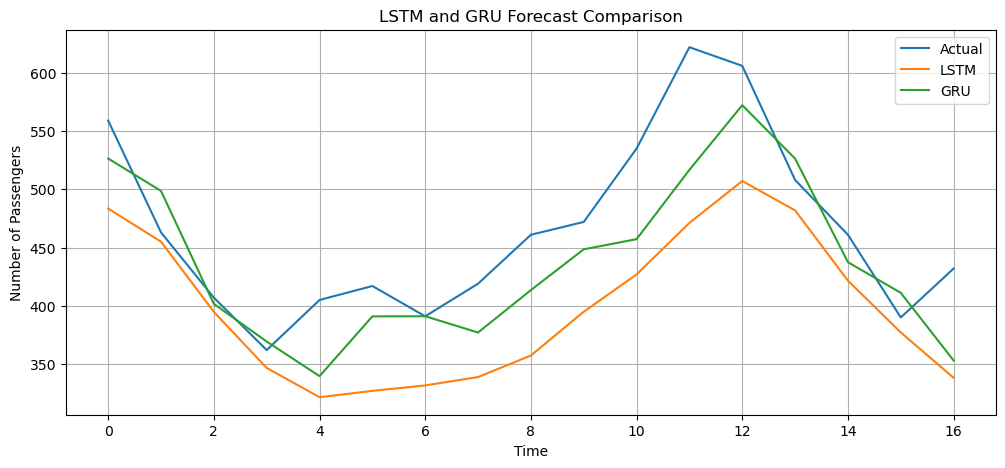

In [26]:
plt.figure(figsize=(12,5))

plt.plot(
    actual,
    label='Actual'
)

plt.plot(
    lstm_predictions,
    label='LSTM'
)

plt.plot(
    gru_predictions,
    label='GRU'
)

plt.title('LSTM and GRU Forecast Comparison')
plt.xlabel('Time')
plt.ylabel('Number of Passengers')

plt.legend()
plt.grid(True)

plt.show()